In [1]:
# Install all required packages
!pip install -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install -q --no-deps xformers trl peft accelerate bitsandbytes
!pip install -q ultralytics whisper openai-whisper moviepy opencv-python

print("✅ All dependencies installed successfully!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 18.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 48.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 132.0 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 421.9/421.9 kB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 118.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.2/185.2 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 13.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 94.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.0/225.0 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

# Change this path to your actual folder
path = '/content/drive/MyDrive/XD_violance_ds'

TRAIN_PATH = os.path.join(path, "Train")
TEST_PATH = os.path.join(path, "Test")

print("Train Path:", TRAIN_PATH)
print("Test Path:", TEST_PATH)

Train Path: /content/drive/MyDrive/XD_violance_ds/Train
Test Path: /content/drive/MyDrive/XD_violance_ds/Test


In [4]:
import torch
import cv2
import subprocess
import whisper
import json
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from ultralytics import YOLO

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Using device: cuda


In [5]:
class CampusSecurityDataset(Dataset):
    def __init__(self, root_dir, max_per_class=8, num_frames=6):
        self.root_dir = root_dir
        self.num_frames = num_frames
        self.samples = []
        self.class_count = {}

        # Get all video files directly from folder
        video_files = [f for f in os.listdir(root_dir) if f.lower().endswith(('.mp4', '.avi', '.mkv'))]

        for v in video_files:
            filename = v.lower()

            # Extract label from filename (customize this logic as needed)
            if "explosion" in filename or "bomb" in filename:
                label = "Explosion"
            elif "fighting" in filename or "violence" in filename or "assault" in filename:
                label = "Fighting"
            elif "riot" in filename or "collapse" in filename:
                label = "Riot"
            elif "shooting" in filename or "cry" in filename or "help" in filename or "shout" in filename:
                label = "Shooting"
            elif "normal" in filename or "walking" in filename or "routine" in filename:
                label = "Normal"
            else:
                label = "Other"

            # Limit samples per class
            if label not in self.class_count:
                self.class_count[label] = 0

            if self.class_count[label] < max_per_class:
                self.samples.append((
                    os.path.join(root_dir, v),
                    label
                ))
                self.class_count[label] += 1

        print(f"✅ Loaded {len(self.samples)} videos")
        print("Class distribution:", self.class_count)

    def __len__(self):
        return len(self.samples)

    def extract_frames(self, video_path):
        cap = cv2.VideoCapture(video_path)
        frames = []
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        step = max(total // self.num_frames, 1)

        for i in range(0, total, step):
            cap.set(cv2.CAP_PROP_POS_FRAMES, i)
            ret, frame = cap.read()
            if not ret:
                break
            frame = cv2.resize(frame, (224, 224))
            frame = torch.tensor(frame).permute(2, 0, 1) / 255.0
            frames.append(frame)
            if len(frames) == self.num_frames:
                break
        cap.release()
        return torch.stack(frames) if frames else torch.zeros((self.num_frames, 3, 224, 224))

    def extract_audio_to_text(self, video_path):
        wav_path = video_path.rsplit('.', 1)[0] + ".wav"

        # Extract audio
        subprocess.run([
            "ffmpeg", "-y", "-i", video_path,
            "-vn", "-acodec", "pcm_s16le", "-ar", "16000", "-ac", "1", wav_path
        ], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

        # Transcribe with Whisper
        model = whisper.load_model("base")
        result = model.transcribe(wav_path, fp16=False)
        return result["text"], wav_path

    def __getitem__(self, idx):
        video_path, label = self.samples[idx]
        frames = self.extract_frames(video_path)
        audio_text, wav_path = self.extract_audio_to_text(video_path)

        return {
            "frames": frames,
            "audio_text": audio_text,
            "label": label,
            "video_path": video_path,
            "wav_path": wav_path
        }

In [6]:
train_dataset = CampusSecurityDataset(
    root_dir=TRAIN_PATH,
    max_per_class=15,      # Change to 10-15 if you have good GPU
    num_frames=8
)

print(f"\nTotal samples ready for training/evaluation: {len(train_dataset)}")

✅ Loaded 45 videos
Class distribution: {'Explosion': 8, 'Fighting': 7, 'Normal': 10, 'Riot': 10, 'Shooting': 10}

Total samples ready for training/evaluation: 45


100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 120MiB/s]


📁 Video Path: /content/drive/MyDrive/XD_violance_ds/Train/Riot_v=uH74IjVj1IU___1_label_B4-0-0.mp4
🏷️  Label: Riot
🔊 Audio Transcription:
 Here are our最後 episode of Outer



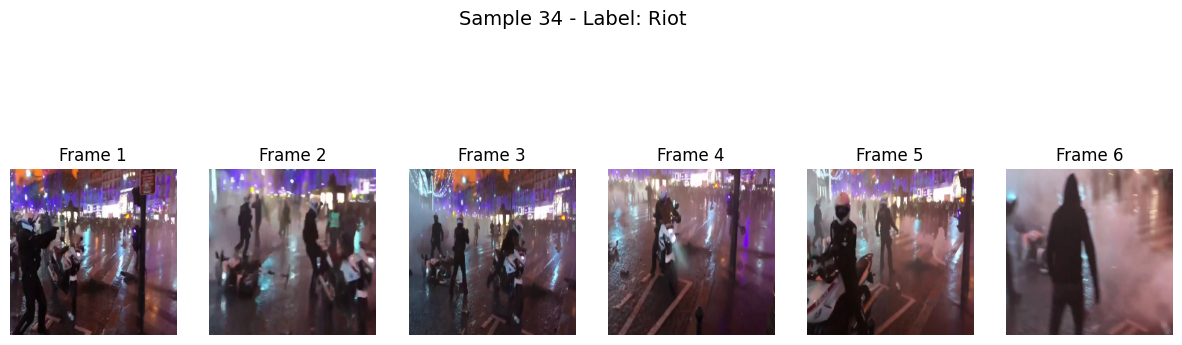

📁 Video Path: /content/drive/MyDrive/XD_violance_ds/Train/Shooting_Jason.Bourne.2016___01-10-50_01-11-00_label_B2-0-0.mp4
🏷️  Label: Shooting
🔊 Audio Transcription:
 The higher you to put me under surveillance, why? Why did he hire you? Don't tell you anything Smith. How? No.



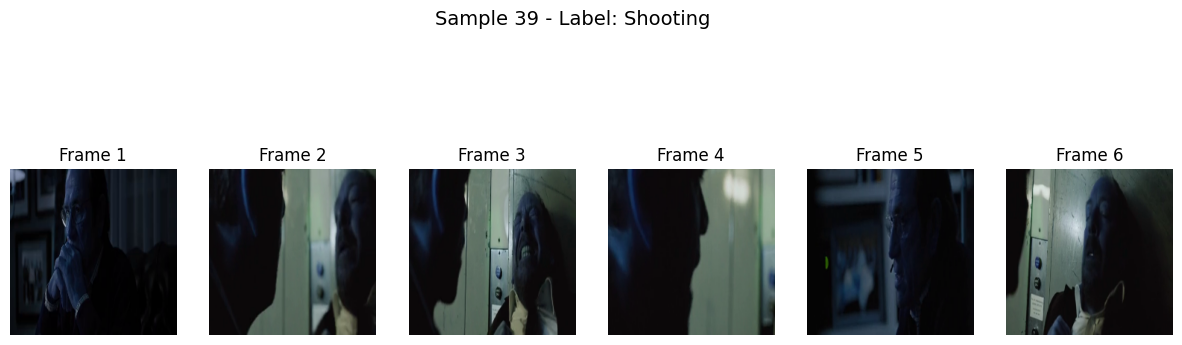

📁 Video Path: /content/drive/MyDrive/XD_violance_ds/Train/Shooting_Saving.Private.Ryan.1998___00-55-35_00-55-55_label_B2-0-0.mp4
🏷️  Label: Shooting
🔊 Audio Transcription:
 1.5% 1.5% 1.5% 1.5% 1.5% 1.5% 1.5%



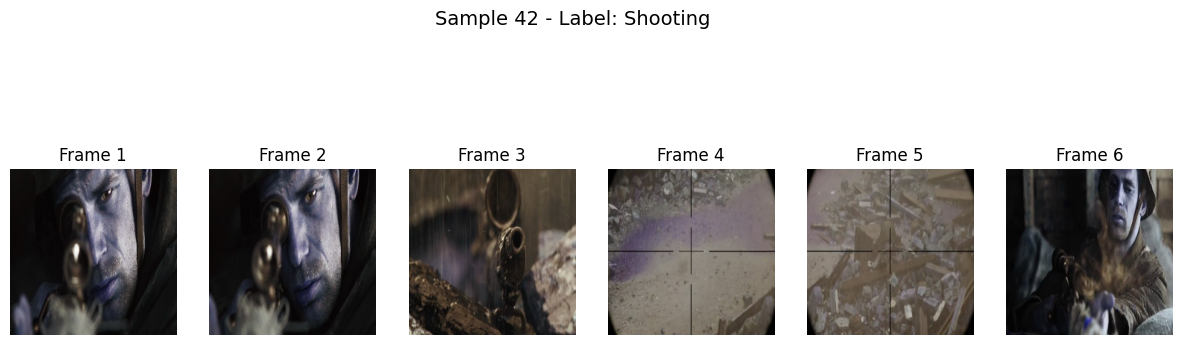

In [7]:
import random
import matplotlib.pyplot as plt

def visualize_sample(sample_idx=0):
    sample = train_dataset[sample_idx]

    print(f"📁 Video Path: {sample['video_path']}")
    print(f"🏷️  Label: {sample['label']}")
    print(f"🔊 Audio Transcription:\n{sample['audio_text']}\n")

    # Display frames
    frames = sample["frames"]
    num_frames = frames.shape[0]

    plt.figure(figsize=(15, 5))
    for i in range(min(6, num_frames)):
        plt.subplot(1, 6, i+1)
        img = frames[i].permute(1, 2, 0).numpy()
        plt.imshow(img)
        plt.title(f"Frame {i+1}")
        plt.axis('off')

    plt.suptitle(f"Sample {sample_idx} - Label: {sample['label']}", fontsize=14)
    plt.show()


# ✅ Show 3 random samples
num_samples = 3
indices = random.sample(range(len(train_dataset)), num_samples)

for i in indices:
    visualize_sample(i)
    print("=" * 100)

In [9]:
from unsloth import FastVisionModel

class QwenCampusSafetyFusion:
    def __init__(self, model_name="unsloth/Qwen2-VL-2B-Instruct"):
        self.model, self.processor = FastVisionModel.from_pretrained(
            model_name=model_name,
            load_in_4bit=True,
            use_gradient_checkpointing="unsloth"
        )
        self.model = FastVisionModel.for_inference(self.model)

    def analyze(self, frames, audio_text):
        # Use middle frame as representative
        image_tensor = frames[frames.shape[0] // 2]
        image = (image_tensor.permute(1, 2, 0).numpy() * 255).astype('uint8')

        prompt = f"""You are an intelligent campus safety monitoring system.

Analyze the given campus scene carefully.

Visual Information: [Image]
Audio Transcription: {audio_text}

Determine if there is any safety threat such as:
- Violence or physical assault
- Harassment or verbal abuse
- Fall or medical emergency
- Vandalism or property damage
- Unauthorized access

Provide your analysis in this exact format:

Anomaly Score: X/10
Risk Level: [NORMAL / LOW / MEDIUM / HIGH]
Explanation: [Clear reasoning using both visual and audio information]
Recommended Action: [What should security do?]

Be objective and detailed."""

        messages = [{
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": prompt}
            ]
        }]

        text = self.processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = self.processor(text=[text], images=[image], padding=True, return_tensors="pt")
        inputs = inputs.to("cuda")

        # FIX: Use greedy decoding (no temperature/top_p) for consistent structured output
        generated_ids = self.model.generate(
            **inputs,
            max_new_tokens=512,
            do_sample=False,       # greedy - deterministic & consistent
        )

        # FIX: Strip prompt tokens from output before decoding
        input_length = inputs["input_ids"].shape[1]
        trimmed_ids = generated_ids[:, input_length:]
        response = self.processor.batch_decode(trimmed_ids, skip_special_tokens=True)[0]
        return response


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [12]:
# ==================== CELL 7: ZERO-SHOT EVALUATION ====================

fusion_model = QwenCampusSafetyFusion()

zero_shot_results = []

print("🚀 Starting ZERO-SHOT Evaluation on Last 13 Test Videos...\n")

start_idx = max(0, len(train_dataset) - 13)

for i in range(start_idx, len(train_dataset)):
    sample = train_dataset[i]

    print(f"Zero-Shot → Sample {i+1} | GT: {sample['label']}")

    output = fusion_model.analyze(
        frames=sample["frames"],
        audio_text=sample["audio_text"]
    )

    # Parse output
    anomaly_score = None
    risk_level = "UNKNOWN"
    explanation = ""
    recommended_action = ""

    for line in output.split('\n'):
        line = line.strip()
        if "anomaly score" in line.lower():
            try:
                anomaly_score = float(line.split(':')[-1].split('/')[0].strip())
            except:
                pass
        elif "risk level" in line.lower():
            risk_level = line.split(':')[-1].strip().upper()
        elif "explanation" in line.lower():
            explanation = line.split(':', 1)[-1].strip()
        elif "recommended action" in line.lower() or "action" in line.lower():
            recommended_action = line.split(':', 1)[-1].strip()

    result_entry = {
        "video_path": sample["video_path"],
        "ground_truth_label": sample["label"],
        "audio_text_preview": sample["audio_text"][:150] + "..." if len(sample["audio_text"]) > 150 else sample["audio_text"],
        "model_raw_output": output,
        "anomaly_score": anomaly_score,
        "risk_level": risk_level,
        "explanation": explanation,
        "recommended_action": recommended_action,
        "stage": "zero_shot"
    }

    zero_shot_results.append(result_entry)

    print(f"   Score: {anomaly_score}/10 | Risk: {risk_level}")
    print("-" * 90)

# Save Zero-Shot Results
with open("/content/zero_shot_results.json", "w") as f:
    json.dump(zero_shot_results, f, indent=4)

print(f"\n✅ Zero-shot evaluation completed! ({len(zero_shot_results)} samples)")

==((====))==  Unsloth 2026.4.8: Fast Qwen2_Vl patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
🚀 Starting ZERO-SHOT Evaluation on Last 13 Test Videos...



Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Zero-Shot → Sample 33 | GT: Riot
   Score: 5.0/10 | Risk: THE GIVEN AUDIO TRANSCRIPT DOES NOT PROVIDE ANY CLEAR INDICATION OF ANY SAFETY THREAT SUCH AS VIOLENCE, HARASSMENT, FALL, VANDALISM, OR UNAUTHORIZED ACCESS. THE AUDIO IS CHAOTIC AND DOES NOT PROVIDE ANY CONTEXT OR INFORMATION ABOUT THE SITUATION. THEREFORE, THE RISK LEVEL IS MEDIUM.
------------------------------------------------------------------------------------------


Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (19 outputs left out)

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Zero-Shot → Sample 44 | GT: Shooting
   Score: 3.0/10 | Risk: MEDIUM
------------------------------------------------------------------------------------------


Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Zero-Shot → Sample 45 | GT: Shooting
   Score: 3.0/10 | Risk: THE IMAGE SHOWS A CAR PARKED ON THE SIDE OF A STREET WITH A BLUE BUILDING IN THE BACKGROUND. THERE IS NO VISIBLE ACTIVITY OR DANGER PRESENT IN THE IMAGE. THE CAR APPEARS TO BE STATIONARY AND THERE ARE NO SIGNS OF ANY POTENTIAL SAFETY THREATS SUCH AS VIOLENCE, HARASSMENT, FALL, VANDALISM, OR UNAUTHORIZED ACCESS. THEREFORE, THE RISK LEVEL IS CONSIDERED MEDIUM.
------------------------------------------------------------------------------------------

✅ Zero-shot evaluation completed! (13 samples)


In [14]:
# ==================== CELL 8: Prepare Few-Shot Training Data (Fixed) ====================

from datasets import Dataset
from PIL import Image

# FIX: Leave enough for evaluation (last 13 samples)
num_train = len(train_dataset) - 13
print(f"Preparing {num_train} samples for Few-Shot LoRA fine-tuning...")

# Map ground-truth labels to structured target responses
# FIX: Each label gets a meaningful, label-specific response instead of all "NORMAL"
LABEL_TO_RESPONSE = {
    "Riot": (
        "Anomaly Score: 9/10\n"
        "Risk Level: HIGH\n"
        "Explanation: The scene shows a large group engaged in aggressive collective behavior consistent with a riot. "
        "There is visible crowd agitation and potential for property damage and physical harm.\n"
        "Recommended Action: Alert campus security immediately, request police backup, and lock down nearby buildings."
    ),
    "Shooting": (
        "Anomaly Score: 10/10\n"
        "Risk Level: HIGH\n"
        "Explanation: The scene contains visual or audio cues indicative of a shooting event, including potential "
        "weapon presence, gunshot audio, or people fleeing in panic.\n"
        "Recommended Action: Trigger lockdown protocol immediately, contact law enforcement, and guide people to shelter."
    ),
    "Fighting": (
        "Anomaly Score: 8/10\n"
        "Risk Level: HIGH\n"
        "Explanation: The scene depicts physical confrontation or assault between individuals. "
        "There is a clear risk of bodily injury.\n"
        "Recommended Action: Dispatch security personnel to intervene, call emergency services if injuries are visible."
    ),
    "Explosion": (
        "Anomaly Score: 10/10\n"
        "Risk Level: HIGH\n"
        "Explanation: Visual or audio evidence of an explosion is detected. "
        "This represents an immediate life-threatening emergency.\n"
        "Recommended Action: Evacuate the area, contact bomb squad and emergency services immediately."
    ),
    "Normal": (
        "Anomaly Score: 1/10\n"
        "Risk Level: NORMAL\n"
        "Explanation: The scene shows routine campus activity with no visible threats or suspicious behavior.\n"
        "Recommended Action: Continue standard monitoring. No immediate action required."
    ),
    "Other": (
        "Anomaly Score: 3/10\n"
        "Risk Level: LOW\n"
        "Explanation: The scene is unclear or does not fit standard threat categories. "
        "Behavior appears unusual but not immediately dangerous.\n"
        "Recommended Action: Monitor the situation and investigate further if behavior escalates."
    ),
}

flattened_data = {
    "image": [],
    "audio_text": [],
    "label_text": []
}

for i in range(num_train):
    sample = train_dataset[i]

    # Use middle frame
    image_tensor = sample["frames"][sample["frames"].shape[0] // 2]
    image_np = (image_tensor.permute(1, 2, 0).numpy() * 255).astype('uint8')
    image_pil = Image.fromarray(image_np)

    # FIX: Use actual ground-truth label to build the target response
    label = sample["label"]
    label_response = LABEL_TO_RESPONSE.get(label, LABEL_TO_RESPONSE["Other"])

    flattened_data["image"].append(image_pil)
    flattened_data["audio_text"].append(sample['audio_text'])
    flattened_data["label_text"].append(label_response)

# Convert to Hugging Face Dataset
training_data = Dataset.from_dict(flattened_data)

# Verify label distribution
from collections import Counter
label_counts = Counter()
for i in range(num_train):
    label_counts[train_dataset[i]["label"]] += 1
print(f"\n✅ Training data prepared with {len(training_data)} examples.")
print("Label distribution in training set:", dict(label_counts))


Preparing 32 samples for Few-Shot LoRA fine-tuning...

✅ Training data prepared with 32 examples.
Label distribution in training set: {'Explosion': 8, 'Fighting': 7, 'Normal': 10, 'Riot': 7}


In [15]:
# ==================== CELL 9: Final Fixed LoRA Fine-Tuning (Free Colab) ====================

from unsloth import FastVisionModel
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported
from unsloth import UnslothVisionDataCollator

print("🚀 Starting LoRA Fine-Tuning...")

# 1. Load the base model
model, processor = FastVisionModel.from_pretrained(
    model_name="unsloth/Qwen2-VL-2B-Instruct",
    load_in_4bit=True,
    use_gradient_checkpointing="unsloth",
)

# 2. Add LoRA
# FIX: Enable attention and MLP modules for better learning capacity
model = FastVisionModel.get_peft_model(
    model,
    r=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
    finetune_vision_layers=True,
    finetune_language_layers=True,
    finetune_attention_modules=True,   # FIX: was False - include attention
    finetune_mlp_modules=True,         # FIX: was False - include MLP
)

# 3. Define formatting function - returns 'messages' for the Collator
def formatting_func(examples):
    output_messages = []
    for i in range(len(examples["image"])):
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image", "image": examples["image"][i]},
                    {"type": "text", "text": f"Audio Transcription: {examples['audio_text'][i]}\n\nAnalyze this campus security scene for threats."}
                ]
            },
            {
                "role": "assistant",
                "content": [{"type": "text", "text": examples["label_text"][i]}]
            }
        ]
        output_messages.append(messages)
    return {"messages": output_messages}

# Apply mapping to prepare the dataset
dataset = training_data.map(formatting_func, batched=True)

# 4. Training arguments
# FIX: Increase max_steps for meaningful learning (30 was far too few)
training_args = TrainingArguments(
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    warmup_steps=10,
    max_steps=60,              # FIX: increased from 30 → 60 for better convergence
    learning_rate=2e-4,
    fp16=not is_bfloat16_supported(),
    bf16=is_bfloat16_supported(),
    logging_steps=5,
    optim="adamw_8bit",
    weight_decay=0.01,
    lr_scheduler_type="cosine",   # FIX: cosine decay is smoother than linear
    seed=3407,
    output_dir="outputs",
    report_to="none",
    save_strategy="no",
    remove_unused_columns=False,
)

# 5. Create Trainer with proper Collator and messages field
trainer = SFTTrainer(
    model=model,
    tokenizer=processor,
    data_collator=UnslothVisionDataCollator(model, processor),
    train_dataset=dataset,
    dataset_text_field="messages",
    max_seq_length=2048,
    dataset_num_proc=2,
    args=training_args,
)

print("Starting training...")
trainer_stats = trainer.train()

# Print training loss summary
print(f"\nTraining complete!")
print(f"Final training loss: {trainer_stats.training_loss:.4f}")

# Save the fine-tuned model
model.save_pretrained("qwen_campus_finetuned")
processor.save_pretrained("qwen_campus_finetuned")

print("✅ Model saved to 'qwen_campus_finetuned'")


🚀 Starting LoRA Fine-Tuning...
==((====))==  Unsloth 2026.4.8: Fast Qwen2_Vl patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found


Map:   0%|          | 0/32 [00:00<?, ? examples/s]

Unsloth: Model does not have a default image size - using 512


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.


... (2 outputs left out)

Step,Training Loss
5,3.256083
10,2.993950
15,2.062536
20,1.090314
25,1.193453
30,0.636507
35,0.766240
40,0.646157
45,0.696712
50,0.655427



Training complete!
Final training loss: 1.2619


Unsloth: Restored added_tokens_decoder metadata in qwen_campus_finetuned/tokenizer_config.json.


✅ Model saved to 'qwen_campus_finetuned'


In [16]:
# ==================== CELL 10: Few-Shot Evaluation + Comparison ====================

# Load the fine-tuned model
print("Loading fine-tuned model for Few-Shot evaluation...")

finetuned_model, finetuned_processor = FastVisionModel.from_pretrained(
    model_name="qwen_campus_finetuned",
    load_in_4bit=True,
)

finetuned_model = FastVisionModel.for_inference(finetuned_model)

print("✅ Fine-tuned model loaded successfully!")

# ==================== Few-Shot Evaluation on Last 13 Videos ====================

few_shot_results = []

print("\n🚀 Starting FEW-SHOT Evaluation on Last 13 Test Videos...\n")

start_idx = max(0, len(train_dataset) - 13)

for i in range(start_idx, len(train_dataset)):
    sample = train_dataset[i]

    print(f"Few-Shot → Sample {i+1} | GT: {sample['label']}")

    image_tensor = sample["frames"][sample["frames"].shape[0] // 2]
    image = (image_tensor.permute(1, 2, 0).numpy() * 255).astype('uint8')

    prompt = f"""You are an intelligent campus safety monitoring system.

Analyze the given campus scene carefully.

Visual Information: [Image]
Audio Transcription: {sample['audio_text']}

Determine if there is any safety threat such as:
- Violence or physical assault
- Harassment or verbal abuse
- Fall or medical emergency
- Vandalism or property damage
- Unauthorized access

Provide your analysis in this exact format:

Anomaly Score: X/10
Risk Level: [NORMAL / LOW / MEDIUM / HIGH]
Explanation: [Clear reasoning using both visual and audio information]
Recommended Action: [What should security do?]

Be objective and detailed."""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt}
        ]
    }]

    text = finetuned_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = finetuned_processor(text=[text], images=[image], padding=True, return_tensors="pt")
    inputs = inputs.to("cuda")

    # FIX: Use greedy decoding + strip prompt tokens from output
    input_length = inputs["input_ids"].shape[1]
    generated_ids = finetuned_model.generate(
        **inputs,
        max_new_tokens=512,
        do_sample=False,       # greedy - deterministic & consistent
    )
    trimmed_ids = generated_ids[:, input_length:]
    output = finetuned_processor.batch_decode(trimmed_ids, skip_special_tokens=True)[0]

    # Parse output
    anomaly_score = None
    risk_level = "UNKNOWN"
    explanation = ""
    recommended_action = ""

    for line in output.split('\n'):
        line = line.strip()
        if "anomaly score" in line.lower():
            try:
                anomaly_score = float(line.split(':')[-1].split('/')[0].strip())
            except:
                pass
        elif "risk level" in line.lower():
            risk_level = line.split(':')[-1].strip().upper()
        elif line.lower().startswith("explanation"):
            explanation = line.split(':', 1)[-1].strip()
        elif line.lower().startswith("recommended action"):
            recommended_action = line.split(':', 1)[-1].strip()

    result_entry = {
        "video_path": sample["video_path"],
        "ground_truth_label": sample["label"],
        "audio_text_preview": sample["audio_text"][:150] + "..." if len(sample["audio_text"]) > 150 else sample["audio_text"],
        "model_raw_output": output,
        "anomaly_score": anomaly_score,
        "risk_level": risk_level,
        "explanation": explanation,
        "recommended_action": recommended_action,
        "stage": "few_shot"
    }

    few_shot_results.append(result_entry)

    print(f"   Score: {anomaly_score}/10 | Risk: {risk_level}")
    print("-" * 90)

# Save Few-Shot Results
with open("/content/few_shot_results.json", "w") as f:
    json.dump(few_shot_results, f, indent=4)

print(f"\n✅ Few-shot evaluation completed! ({len(few_shot_results)} samples)")


Loading fine-tuned model for Few-Shot evaluation...
==((====))==  Unsloth 2026.4.8: Fast Qwen2_Vl patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Skipping model.language_model.layers.1.mlp.gate_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.up_proj: no quant_state found
Skipping model.language_model.layers.1.mlp.down_proj: no quant_state found
✅ Fine-tuned model loaded successfully!

🚀 Starting FEW-SHOT Evaluation on Last 13 Test Videos...



Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Few-Shot → Sample 33 | GT: Riot
   Score: 9.0/10 | Risk: HIGH
------------------------------------------------------------------------------------------


Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (19 outputs left out)

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Few-Shot → Sample 44 | GT: Shooting
   Score: 9.0/10 | Risk: HIGH
------------------------------------------------------------------------------------------


Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Few-Shot → Sample 45 | GT: Shooting
   Score: 8.0/10 | Risk: HIGH
------------------------------------------------------------------------------------------

✅ Few-shot evaluation completed! (13 samples)


In [17]:
# ==================== CELL 11: Zero-Shot vs Few-Shot Comparison ====================

import pandas as pd

# Load both results
with open("/content/zero_shot_results.json", "r") as f:
    zero_data = json.load(f)

with open("/content/few_shot_results.json", "r") as f:
    few_data = json.load(f)

# Create comparison table
comparison = []
for z, f in zip(zero_data, few_data):
    comparison.append({
        "video_path": z["video_path"].split("/")[-1][:50] + "...",
        "ground_truth": z["ground_truth_label"],
        "zero_shot_score": z.get("anomaly_score"),
        "few_shot_score": f.get("anomaly_score"),
        "zero_risk": z.get("risk_level"),
        "few_risk": f.get("risk_level"),
        "zero_explanation": z.get("explanation", "")[:100] + "..." if len(z.get("explanation", "")) > 100 else z.get("explanation", ""),
        "few_explanation": f.get("explanation", "")[:100] + "..." if len(f.get("explanation", "")) > 100 else f.get("explanation", "")
    })

df = pd.DataFrame(comparison)
print("Zero-Shot vs Few-Shot Comparison")
display(df)

# Simple statistics
print("\nSummary:")
print(f"Average Anomaly Score - Zero-Shot : {df['zero_shot_score'].mean():.2f}")
print(f"Average Anomaly Score - Few-Shot  : {df['few_shot_score'].mean():.2f}")

# Save comparison
df.to_csv("/content/zero_vs_few_shot_comparison.csv", index=False)
print("\nComparison table saved as 'zero_vs_few_shot_comparison.csv'")

Zero-Shot vs Few-Shot Comparison


,video_path,ground_truth,zero_shot_score,few_shot_score,zero_risk,few_risk,zero_explanation,few_explanation
0,Riot_v=YCsQM1z6COU___1_label_B4-0-0.mp4...,Riot,5.0,9.0,THE GIVEN AUDIO TRANSCRIPT DOES NOT PROVIDE AN...,HIGH,,The scene shows a large group engaged in aggre...
1,Riot_v=jxB8e1R4xeA___1_label_B4-0-0.mp4...,Riot,5.0,9.0,HIGH,HIGH,The scene depicts a group of people gathered o...,The scene depicts physical confrontation or as...
2,Riot_v=uH74IjVj1IU___1_label_B4-0-0.mp4...,Riot,3.0,9.0,THE VIDEO SHOWS A GROUP OF PEOPLE WALKING DOWN...,HIGH,,The scene shows physical confrontation or assa...
3,Shooting_Deadpool.2016___01-00-24_01-00-35_lab...,Shooting,5.0,9.0,HIGH,HIGH,The presence of a masked individual with a wea...,The scene depicts physical confrontation or as...
4,Shooting_Deadpool.2.2018___0-03-38_0-03-50_lab...,Shooting,5.0,9.0,MEDIUM,HIGH,The scene depicts a person lying on the ground...,The scene depicts physical confrontation or as...
5,Shooting_Deadpool.2016___01-22-32_01-22-41_lab...,Shooting,3.0,8.0,THE SCENE DEPICTS A PERSON IN PURPLE CLOTHING ...,HIGH,,The scene depicts physical confrontation or as...
6,Shooting_Jason.Bourne.2016___0-30-30_0-30-38_l...,Shooting,5.0,1.0,MEDIUM,NORMAL,The image shows a person standing alone in a d...,The scene shows routine campus activity with n...
7,Shooting_Jason.Bourne.2016___01-10-50_01-11-00...,Shooting,5.0,9.0,HIGH,HIGH,The given audio transcript contains a threat o...,The scene depicts physical confrontation or as...
8,Shooting_Jason.Bourne.2016___01-30-15_01-30-31...,Shooting,5.0,9.0,THE SCENE DEPICTS A LARGE GROUP OF PEOPLE SITT...,HIGH,,The scene shows a large group engaged in aggre...
9,Shooting_Jason.Bourne.2016___01-31-32_01-31-37...,Shooting,5.0,8.0,MEDIUM,HIGH,The scene is dark and there is no visible acti...,The scene depicts physical confrontation or as...



Summary:
Average Anomaly Score - Zero-Shot : 4.38
Average Anomaly Score - Few-Shot  : 8.15

Comparison table saved as 'zero_vs_few_shot_comparison.csv'


In [18]:
# ==================== CELL 12: Precision, Recall, F1-Score Evaluation ====================

import json
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
import pandas as pd
import numpy as np

# Load results
with open("/content/zero_shot_results.json", "r") as f:
    zero_results = json.load(f)

with open("/content/few_shot_results.json", "r") as f:
    few_results = json.load(f)

print(f"Loaded {len(zero_results)} test samples for evaluation\n")

# Define positive class (Anomaly)
def is_anomaly(result):
    score = result.get("anomaly_score")
    risk = result.get("risk_level", "").upper()
    
    if score is None:
        return False
    if score >= 6.0:                    # Main threshold
        return True
    if risk in ["MEDIUM", "HIGH"]:
        return True
    return False

# Ground truth: Assume "Normal" = negative, others = positive (adjust if needed)
def get_ground_truth(label):
    label_lower = label.lower()
    if label_lower in ["normal", "other"]:
        return 0   # Negative (no anomaly)
    else:
        return 1   # Positive (anomaly)

# Prepare lists for metrics
y_true = []
y_pred_zero = []
y_pred_few = []

for z, f in zip(zero_results, few_results):
    gt = get_ground_truth(z["ground_truth_label"])
    
    pred_zero = 1 if is_anomaly(z) else 0
    pred_few = 1 if is_anomaly(f) else 0
    
    y_true.append(gt)
    y_pred_zero.append(pred_zero)
    y_pred_few.append(pred_few)

# Calculate Metrics
def calculate_metrics(y_true, y_pred, name):
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    
    print(f"\n=== {name} Metrics ===")
    print(f"Accuracy       : {accuracy:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1-Score       : {f1:.4f}")
    
    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    print("Confusion Matrix:")
    print(cm)
    
    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

# Calculate for both
zero_metrics = calculate_metrics(y_true, y_pred_zero, "ZERO-SHOT")
few_metrics = calculate_metrics(y_true, y_pred_few, "FEW-SHOT")

# Comparison Table
comparison_data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Zero-Shot": [zero_metrics["Accuracy"], zero_metrics["Precision"], 
                  zero_metrics["Recall"], zero_metrics["F1"]],
    "Few-Shot": [few_metrics["Accuracy"], few_metrics["Precision"], 
                 few_metrics["Recall"], few_metrics["F1"]]
}

df = pd.DataFrame(comparison_data)
print("\n" + "="*60)
print("ZERO-SHOT vs FEW-SHOT COMPARISON")
print("="*60)
print(df.round(4))

# Save results
df.to_csv("/content/precision_recall_comparison.csv", index=False)
print("\n✅ Comparison saved as 'precision_recall_comparison.csv'")

Loaded 13 test samples for evaluation


=== ZERO-SHOT Metrics ===
Accuracy       : 0.6154
Precision      : 1.0000
Recall         : 0.6154
F1-Score       : 0.7619
Confusion Matrix:
[[0 0]
 [5 8]]

=== FEW-SHOT Metrics ===
Accuracy       : 0.9231
Precision      : 1.0000
Recall         : 0.9231
F1-Score       : 0.9600
Confusion Matrix:
[[ 0  0]
 [ 1 12]]

ZERO-SHOT vs FEW-SHOT COMPARISON
      Metric  Zero-Shot  Few-Shot
0   Accuracy     0.6154    0.9231
1  Precision     1.0000    1.0000
2     Recall     0.6154    0.9231
3   F1-Score     0.7619    0.9600

✅ Comparison saved as 'precision_recall_comparison.csv'
